#Dataset Description: Customer Churn Dataset
🔹 Overview

The dataset is used for predicting whether a customer will leave a service (churn) or continue using it. It contains customer demographic, financial, and account activity information.

🔹 Shape of Dataset
Rows (Instances): 10,000
Columns (Features): 12

👉 Shape: (10000, 12)

Each row represents one customer, and each column represents a specific attribute of that customer.

🔹 Attribute Description
customer_id → Unique identifier for each customer

credit_score → Customer’s credit score (financial reliability indicator)

country → Country of the customer (e.g., France, Spain)

gender → Gender of the customer (Male/Female)

age → Age of the customer

tenure → Number of years the customer has been with the company

balance → Account balance of the customer

products_number → Number of products used by the customer

credit_card → Whether the customer has a credit card (1 = Yes, 0 = No)

active_member → Whether the customer is an active member (1 = Yes, 0 = No)

estimated_salary → Estimated salary of the customer

churn → Target variable (1 = Customer left, 0 = Customer stayed)

Feature Types

✅ Numerical Features
credit_score
age
tenure
balance
products_number
estimated_salary

✅ Categorical Features
country
gender

✅ Binary Features
credit_card
active_member
churn

🔹 Target Variable
churn
1 → Customer left the service
0 → Customer stayed

👉 This makes it a binary classification problem

🔹 Key Characteristics of Dataset
Medium-sized dataset (10K records)
Mix of categorical and numerical features
Real-world business problem (customer retention)
Suitable for:
Logistic Regression
Random Forest
XGBoost
Neural Networks

🔹 Purpose of Dataset

The main goal is to:

Predict customer churn
Identify factors influencing customer leaving behavior
Help businesses improve customer retention strategies

#Import Python Libraries


In [ ]:
# Standard imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Metrics & utilities
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import joblib
import warnings
warnings.filterwarnings("ignore")

# Display settings
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
pd.set_option('display.max_columns', 200)

#Load Python Libraries

In [ ]:
# Load dataset (adjust path if needed)
df = pd.read_csv("customer_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (10000, 12)


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1.0
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0.0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1.0
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0.0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.1,0.0


# #Step 3. Initial inspection

In [ ]:
# Info & Summary
display(df.info())
display(df.describe(include='all'). T)

NameError: name 'df' is not defined

**Observations from Data Summary**
The dataset contains 10,000 rows and 12 columns, with a mix of numerical and categorical features.

Missing values are present in credit_score (161), estimated_salary (79), and churn (1), which must be handled before modeling.
Some columns have incorrect data types:

**credit_score **→ object (should be numeric)

**estimated_salary** → object (should be float)

The target variable churn is imbalanced (~20% positive class), indicating class imbalance.

Most customers are from France, and gender distribution is fairly balanced.

Average customer age is around 39 years, with a wide range (18–92).

Many customers have zero balance, indicating inactive or new accounts.

Majority of customers are active members (51%) and credit card holders (~70%).

 #Target distributions analysis

In [ ]:
# Target distribution
print("\nChurn value counts:")
print(df['churn'].value_counts(normalize=False))
print("\nChurn proportion:")
print(df['churn'].value_counts(normalize=True))


Churn value counts:
churn
0.0    7962
1.0    2037
Name: count, dtype: int64

Churn proportion:
churn
0.0    0.79628
1.0    0.20372
Name: proportion, dtype: float64


#Step 4. Exploratory Data Analysis (visualizations)

#Data Type Correction

In [ ]:
df['credit_score'] = pd.to_numeric(df['credit_score'], errors='coerce')
df['estimated_salary'] = pd.to_numeric(df['estimated_salary'], errors='coerce')

#Distribution plots

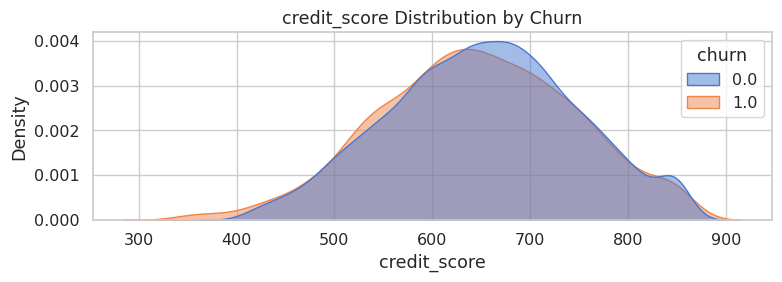

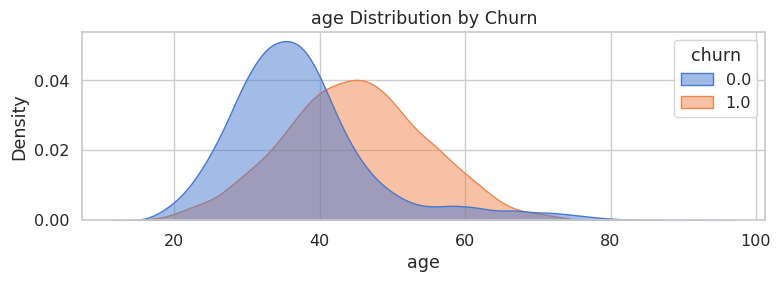

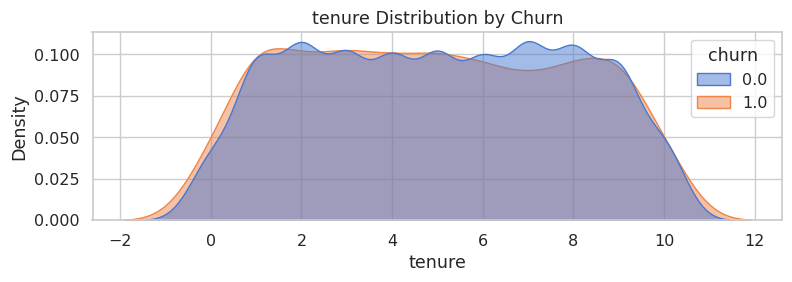

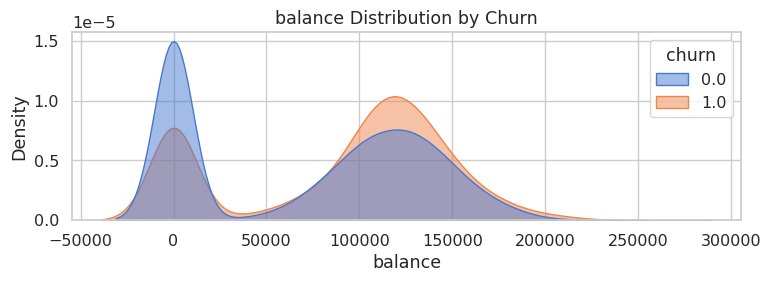

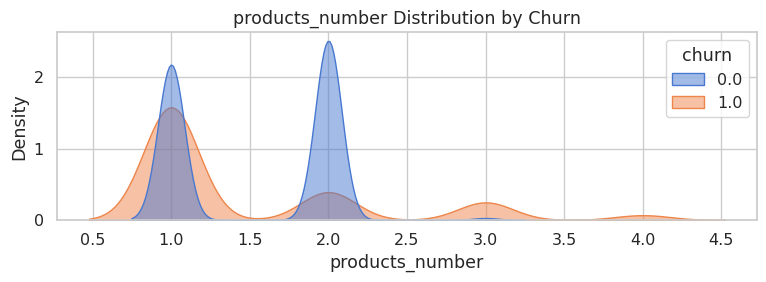

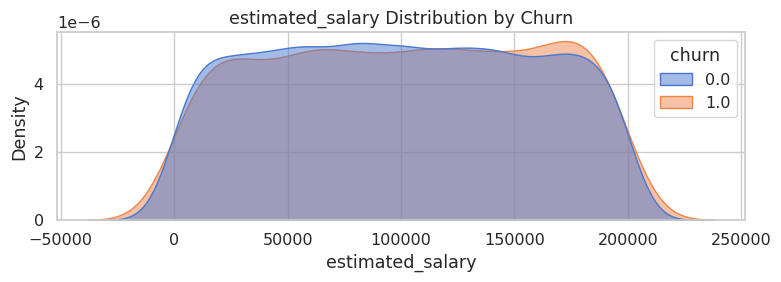

In [ ]:
num_cols = ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary']

# --- Distribution plots
for col in num_cols:
    plt.figure(figsize=(8,3))
    sns.kdeplot(data=df, x=col, hue='churn', fill=True, common_norm=False, alpha=0.5)
    plt.title(f'{col} Distribution by Churn')
    plt.tight_layout()
    plt.show()

#- Pairplot (sampled for speed)

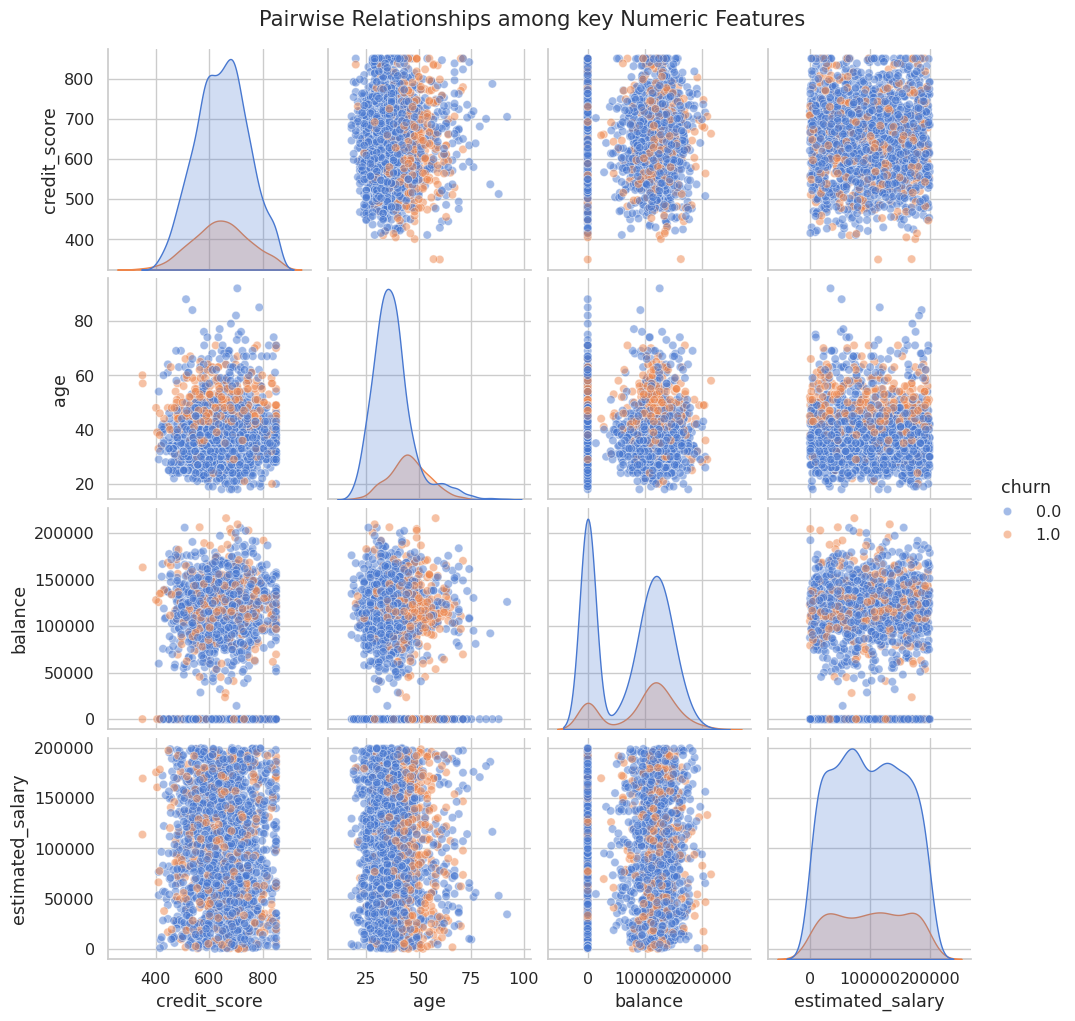

In [ ]:
# --- Pairplot (sampled for speed)
sns.pairplot(df.sample(frac=0.2, random_state=42),
             vars=['credit_score', 'age', 'balance', 'estimated_salary'],
            hue='churn', diag_kind='kde', plot_kws={'alpha':0.5})
plt.suptitle('Pairwise Relationships among key Numeric Features', y=1.02)
plt.show()

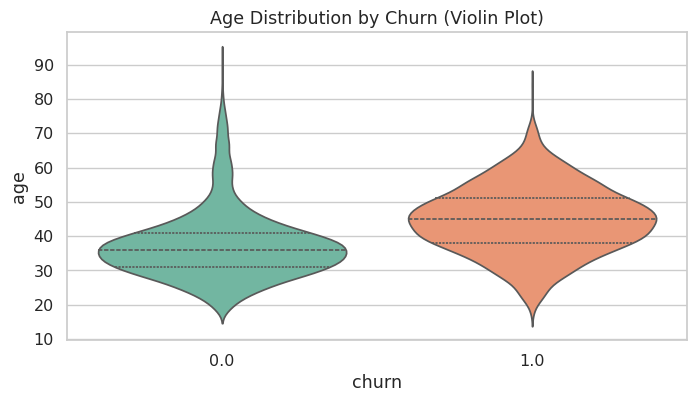

In [ ]:
# --- Violin plot for Age
plt.figure(figsize=(8,4))
sns.violinplot(data=df, x='churn', y='age', inner='quart', palette='Set2')
plt.title('Age Distribution by Churn (Violin Plot)')
plt.show()

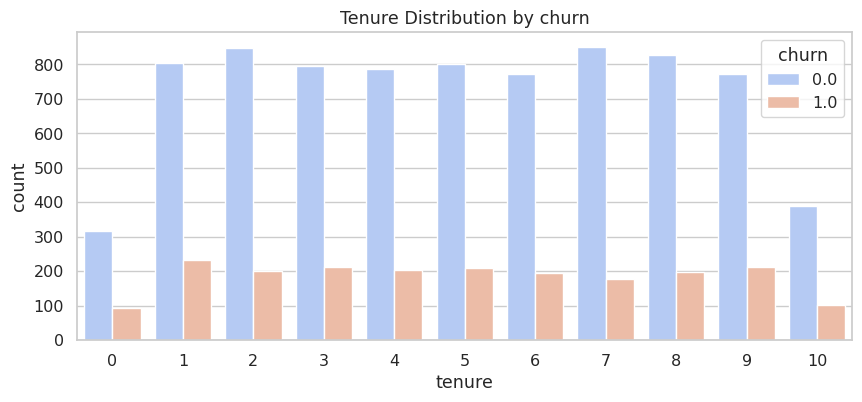

In [ ]:
# --- Trnure distribution
plt.figure(figsize=(10,4))
sns.countplot(data=df, x='tenure', hue='churn', palette='coolwarm')
plt.title('Tenure Distribution by churn')
plt.show()

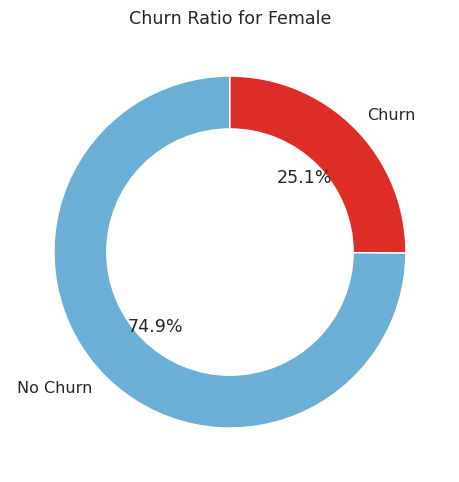

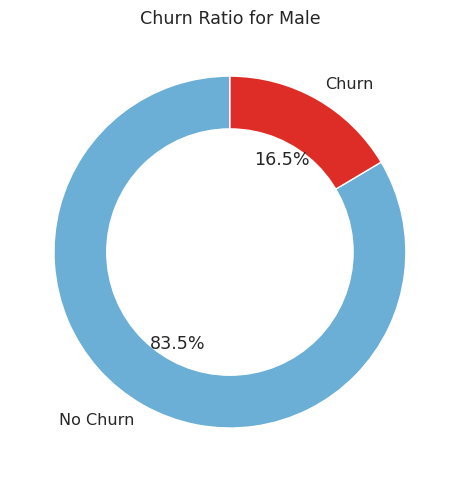

In [ ]:
# --- Gender vs Churn Donut Chart
gender_counts = df.groupby('gender')['churn'].value_counts(normalize=True).unstack().fillna(0)
for gender in gender_counts.index:
    plt.figure(figsize=(5,5))
    plt.pie(gender_counts.loc[gender], labels=['No Churn', 'Churn'],
            autopct='%1.1f%%', startangle=90, colors=['#6baed6', '#de2d26'])
    center = plt.Circle((0,0),0.70, fc='white')
    fig = plt.gcf()
    fig.gca().add_artist(center)
    plt.title(f'Churn Ratio for {gender}')
    plt.tight_layout()
    plt.show()

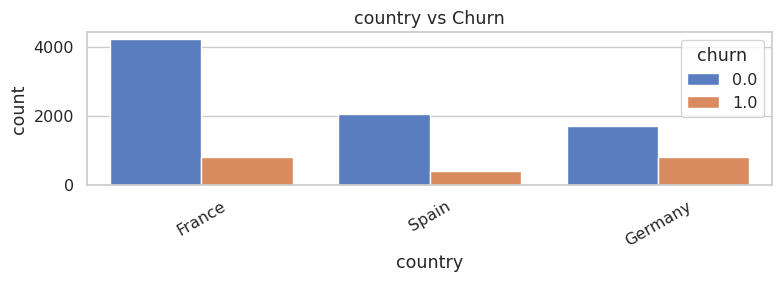

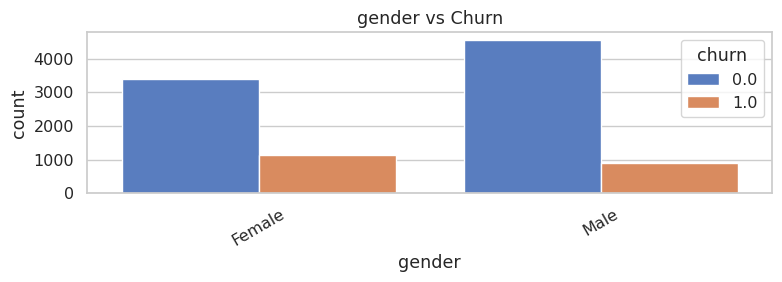

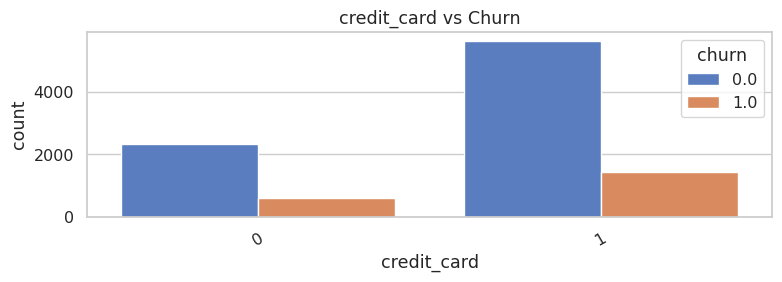

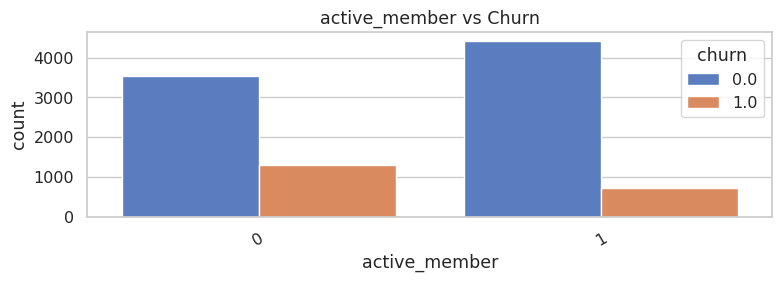

In [ ]:
# --- Categorical features
cat_cols = ['country', 'gender', 'credit_card', 'active_member']
for c in cat_cols:
    plt.figure(figsize=(8,3))
    sns.countplot(data=df, x=c, hue='churn')
    plt.title(f'{c} vs Churn')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [ ]:
# --- Numeric Corellation heatmap
numeric_data = df[num_cols]  # use the numeric columns from your feature-engineered dataframe
corr = numeric_data.corr()
corr.style.background_gradient(cmap='coolwarm')

,credit_score,age,tenure,balance,products_number,estimated_salary
credit_score,1.000000,-0.001585,0.001169,0.004158,0.013317,-0.001640
age,-0.001585,1.000000,-0.009997,0.028308,-0.030680,-0.005763
tenure,0.001169,-0.009997,1.000000,-0.012254,0.013444,0.006200
balance,0.004158,0.028308,-0.012254,1.000000,-0.304180,0.011602
products_number,0.013317,-0.030680,0.013444,-0.304180,1.000000,0.014442
estimated_salary,-0.001640,-0.005763,0.006200,0.011602,0.014442,1.000000


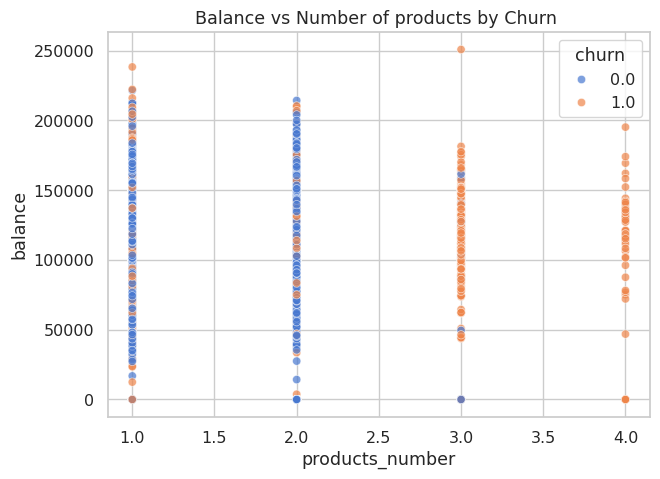

In [ ]:
# --- Balance vs Products scatter
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='products_number', y='balance', hue='churn', alpha=0.7)
plt.title('Balance vs Number of products by Churn ')
plt.show()

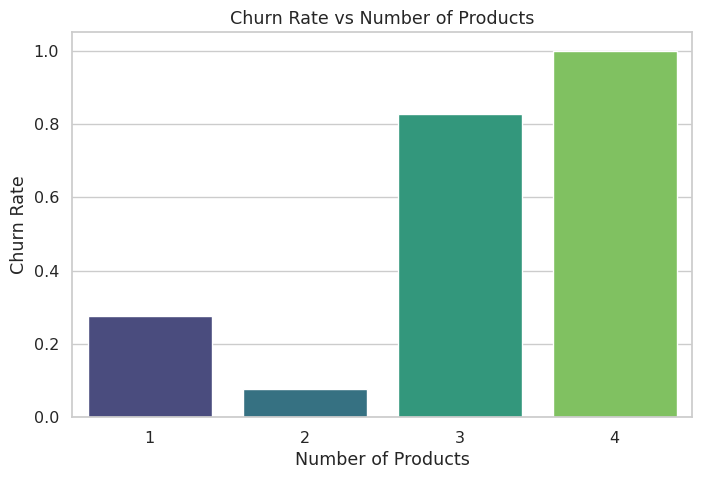

In [ ]:
# --- Aggregate churn rate per number of products
churn_rate = df.groupby('products_number')['churn'].mean().reset_index()

# Plot churn rate
plt.figure(figsize=(8,5))
sns.barplot(data=churn_rate, x='products_number', y='churn', palette='viridis')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate')
plt.title('Churn Rate vs Number of Products')
plt.show()

#Data Preprocessing & cleanning

## Missing values

In [ ]:
# Missing values
print("\nMissing values per column:")
df.isnull().sum()



Missing values per column:


,0
customer_id,0
credit_score,164
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


## Visualizing Missing Data using a seaborn heatmap.

<Axes: >

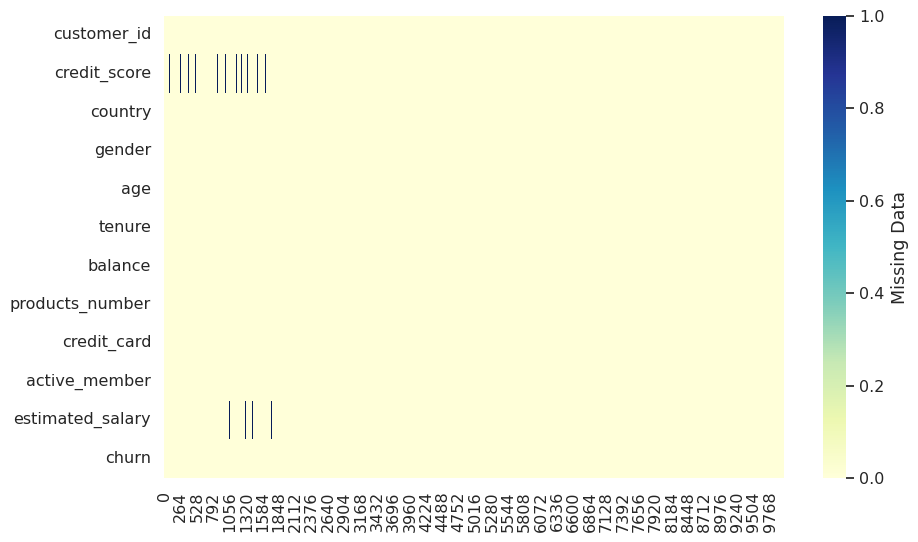

In [ ]:
# Visualizing Missing Data using a seaborn heatmap.
plt.figure(figsize=(10,6))
sns.heatmap(df.isna().transpose(),
            cmap="YlGnBu",
            cbar_kws={'label': 'Missing Data'})

#Handling Missing Values

In [ ]:
df['credit_score'].fillna(df['credit_score'].mean(), inplace=True)
df['estimated_salary'].fillna(df['estimated_salary'].mean(), inplace=True)
# Remove rows where churn value is missing (NaN)
df = df.dropna(subset=['churn'])
df.head()
df.columns


Index(['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure',
       'balance', 'products_number', 'credit_card', 'active_member',
       'estimated_salary', 'churn'],
      dtype='object')

#verify missing values

In [ ]:
df.isnull().sum()

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


#Removing Irrelevant Features

In [ ]:
df.drop('customer_id', axis=1, inplace=True)
df.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,619.0,France,Female,42,2,0.00,1,1,1,101348.88,1.0
1,608.0,Spain,Female,41,1,83807.86,1,0,1,112542.58,0.0
2,502.0,France,Female,42,8,159660.80,3,1,0,113931.57,1.0
3,699.0,France,Female,39,1,0.00,2,0,0,93826.63,0.0
4,850.0,Spain,Female,43,2,125510.82,1,1,1,79084.10,0.0


  #Observation :
  Drop unnecessary columns that do not contribute to prediction.


#Features Engineering

Create meaningful features: e.g balance per product, age group, salary bracket and handle missing values.

In [ ]:
# Feature engineering examples
df_fe = df.copy()

# Balance per product
df_fe['balance_per_product'] = df_fe['balance'] / (df_fe['products_number'].replace(0, np.nan))
df_fe['balance_per_product'].fillna(0, inplace=True)

# Salary to balance ratio
df_fe['salary_balance_ratio'] = df_fe['estimated_salary'] / (df_fe['balance'].replace(0, np.nan))
df_fe['salary_balance_ratio'].replace([np.inf, -np.inf], np.nan, inplace=True)
df_fe['salary_balance_ratio'].fillna(df_fe['salary_balance_ratio'].median(), inplace=True)

# Age group
bins = [0,25,35,45,55,65,100]
labels = ['<25','25-34','35-44','45-54','55-64','65+']
df_fe['age_group'] = pd.cut(df_fe['age'], bins=bins, labels=labels)

# Tenure bucket
df_fe['tenure_bucket'] = pd.cut(df_fe['tenure'], bins=[-1,0,2,5,10,100], labels=['0','1-2','3-5','6-10','10+'])

# Flag high balance
df_fe['high_balance'] = (df_fe['balance'] > df_fe['balance'].quantile(0.75)).astype(int)

# Quick checks
df_fe[['balance_per_product','salary_balance_ratio','age','age_group','tenure','tenure_bucket','high_balance']].head()

,balance_per_product,salary_balance_ratio,age,age_group,tenure,tenure_bucket,high_balance
0,0.000000,0.838847,42,35-44,2,1-2,0
1,83807.860000,1.342864,41,35-44,1,1-2,0
2,53220.266667,0.713585,42,35-44,8,6-10,1
3,0.000000,0.838847,39,35-44,1,1-2,0
4,125510.820000,0.630098,43,35-44,2,1-2,0


# Step 6. Preprocessing - encoding & scaling
We'll build a preprocessing pipeline that encodes categorical features and scales numerical ones.

In [ ]:
# Define features and target
target = 'churn'

features = [c for c in df_fe.columns if c not in [target] + drop_cols]

numeric_features = ['credit_score','age','tenure','balance','products_number','estimated_salary',
                    'balance_per_product','salary_balance_ratio']
categorical_features = ['country','gender','credit_card','active_member','age_group','tenure_bucket','high_balance']

df_fe[categorical_features] = df_fe[categorical_features].astype('object')

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

Numeric features: ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary', 'balance_per_product', 'salary_balance_ratio']
Categorical features: ['country', 'gender', 'credit_card', 'active_member', 'age_group', 'tenure_bucket', 'high_balance']


#Step 7. Train Test split

In [ ]:
X = df_fe[features]
y = df_fe[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Train churn proportion:', y_train.mean(), 'Test churn proportion:', y_test.mean())

Train shape: (7999, 15) Test shape: (2000, 15)
Train churn proportion: 0.20377547193399176 Test churn proportion: 0.2035


#Step 8. Train Multiple models with a pipeline and compare using cross-validation

In [ ]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=500),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42),
    'GradientBoosting': GradientBoostingClassifier(n_estimators=200, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=42),
    'SVC': SVC(probability=True, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    results[name] = scores
    print(f"{name} AUC: Mean={scores.mean():.4f} Std={scores.std():.4f}")

LogisticRegression AUC: Mean=0.7862 Std=0.0167
RandomForest AUC: Mean=0.8503 Std=0.0089
GradientBoosting AUC: Mean=0.8610 Std=0.0119
AdaBoost AUC: Mean=0.8451 Std=0.0123
SVC AUC: Mean=0.8357 Std=0.0087


# Boxplot of CV AUC scores

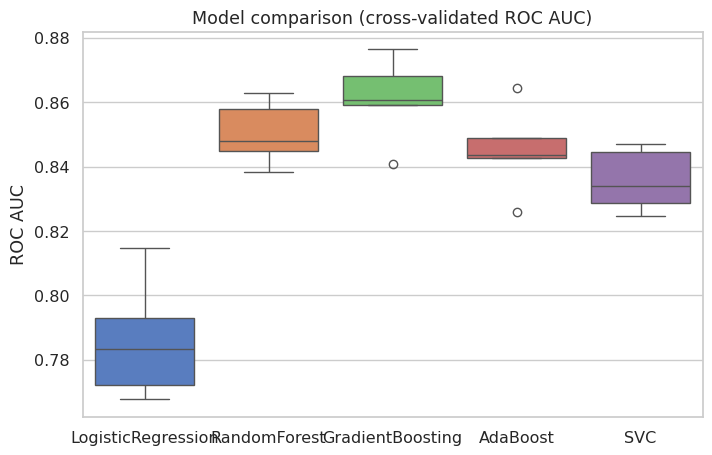

In [ ]:
# Boxplot of CV AUC scores
plt.figure(figsize=(8,5))
sns.boxplot(data=[results[m] for m in list(results.keys())])
plt.xticks(ticks=range(len(results)), labels=list(results.keys()))
plt.ylabel('ROC AUC')
plt.title('Model comparison (cross-validated ROC AUC)')
plt.show()

#Step 9. Fit best model on full train set and evaluate on test set
Select best model by mean CV AUC above and evaluate standard metrics on the test set

Test Accuracy: 0.8675
Test Precision: 0.8034
Test Recall: 0.4619
Test F1-score: 0.5866
Test ROC AUC: 0.8693

Classification Report:
              precision    recall  f1-score   support

         0.0       0.88      0.97      0.92      1593
         1.0       0.80      0.46      0.59       407

    accuracy                           0.87      2000
   macro avg       0.84      0.72      0.75      2000
weighted avg       0.86      0.87      0.85      2000



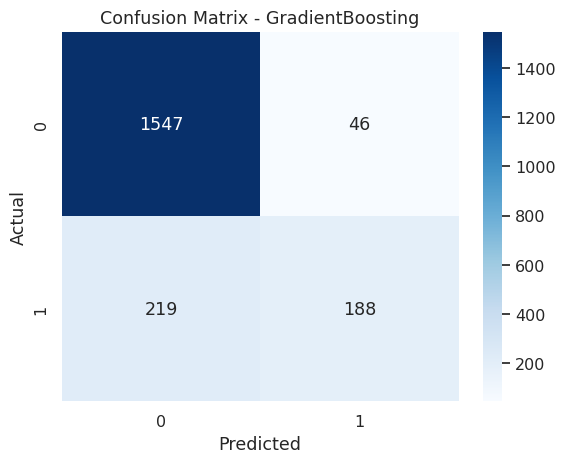

In [ ]:
# Choose best model (automatic pick by mean AUC)
best_name = max(results.keys(), key=lambda k: results[k].mean())
best_name, results[best_name].mean()
('GradientBoosting', np.float64(0.8627777349731776))
best_model = models[best_name]
best_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                ('classifier', best_model)])
best_pipeline.fit(X_train, y_train)

# Predictions
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:,1]

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc = roc_auc_score(y_test, y_proba)

print(f"Test Accuracy: {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall: {rec:.4f}")
print(f"Test F1-score: {f1:.4f}")
print(f"Test ROC AUC: {roc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_name}')
plt.show()

#Step 10. Feature importance

,0
age,0.338029
products_number,0.258537
balance_per_product,0.069209
active_member_0,0.062566
country_Germany,0.052316
balance,0.047147
active_member_1,0.039353
estimated_salary,0.028270
salary_balance_ratio,0.026193
credit_score,0.025195


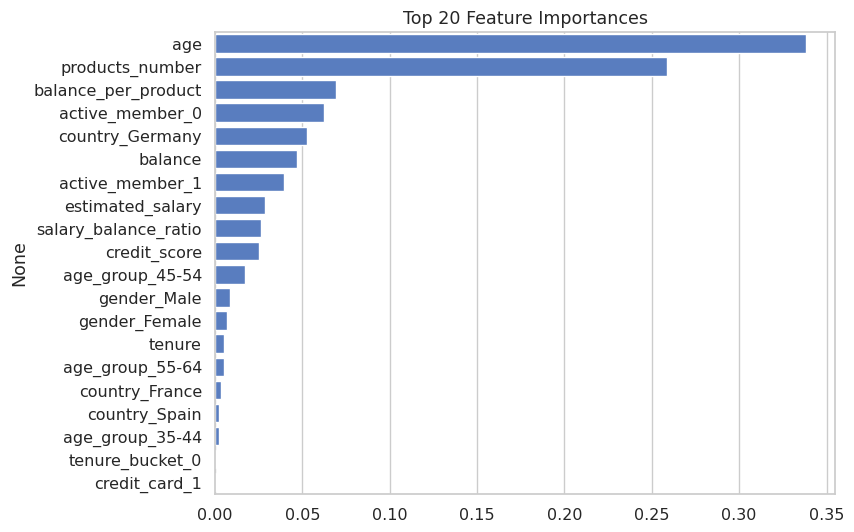

In [ ]:
if hasattr(best_pipeline.named_steps['classifier'], 'feature_importances_'):
    num_feats = numeric_features
    cat_feats = list(best_pipeline.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot'].get_feature_names_out(categorical_features))
    feature_names = num_feats + cat_feats
    importances = best_pipeline.named_steps['classifier'].feature_importances_
    fi = pd.Series(importances, index=feature_names).sort_values(ascending=False)[:20]
    display(fi)
    plt.figure(figsize=(8,6))
    sns.barplot(x=fi.values, y=fi.index)
    plt.title('Top 20 Feature Importances')
    plt.show()
else:
    print('Selected model does not provide feature_importances_ attribute.')

#Step 11. Example: Predict churn for a new customer

In [ ]:
# --- New customer sample ---
sample = {
    'customer_id': 373292028,
    'credit_score': 650,
    'country': 'France',
    'gender': 'Male',
    'age': 40,
    'tenure': 3,
    'balance': 50000.0,
    'products_number': 2,
    'credit_card': 1,
    'active_member': 1,
    'estimated_salary': 60000.0
}

sample_df = pd.DataFrame([sample])

# --- Apply same feature engineering ---
sample_df['balance_per_product'] = sample_df['balance'] / (sample_df['products_number'].replace(0, np.nan))
sample_df['balance_per_product'].fillna(0, inplace=True)

sample_df['salary_balance_ratio'] = sample_df['estimated_salary'] / (sample_df['balance'].replace(0, np.nan))
sample_df['salary_balance_ratio'].replace([np.inf, -np.inf], np.nan, inplace=True)
sample_df['salary_balance_ratio'].fillna(sample_df['salary_balance_ratio'].median(), inplace=True)

bins = [0,25,35,45,55,65,100]
labels = ['<25','25-34','35-44','45-54','55-64','65+']
sample_df['age_group'] = pd.cut(sample_df['age'], bins=bins, labels=labels)

sample_df['tenure_bucket'] = pd.cut(sample_df['tenure'], bins=[-1,0,2,5,10,100], labels=['0','1-2','3-5','6-10','10+'])
sample_df['high_balance'] = (sample_df['balance'] > 50000.0).astype(int)  # can use 75th percentile of training set


# --- Drop ID ---
sample_df = sample_df.drop(columns=['customer_id'])

# --- Predict ---
pred = best_pipeline.predict(sample_df)[0]
prob = best_pipeline.predict_proba(sample_df)[0,1]

print(f'Predicted churn: {pred}, probability of churn: {prob:.3f}')

Predicted churn: 0.0, probability of churn: 0.040


#Findings
redicted churn = 0

👉 The model predicts:

The customer will NOT leave the company
✔ Probability = 0.040 (4%)

👉 This means:

Only 4% chance the customer will churn
Very low risk customer